In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)


Mounted at /content/drive


In [ ]:
!pip install -U ultralytics


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 22.4 MB/s eta 0:00:00


In [ ]:
from ultralytics import YOLO
print("✅ YOLOv8 installed successfully!")


Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
✅ YOLOv8 installed successfully!


In [ ]:
from google.colab import files
uploaded = files.upload()


Saving Pothole detection.v1i.yolov8.zip to Pothole detection.v1i.yolov8.zip


In [ ]:
!unzip "Pothole detection.v1i.yolov8.zip" -d /content/dataset


Archive:  Pothole detection.v1i.yolov8.zip
 extracting: /content/dataset/README.dataset.txt  
 extracting: /content/dataset/README.roboflow.txt  
 extracting: /content/dataset/data.yaml  
   creating: /content/dataset/test/
   creating: /content/dataset/test/images/
 extracting: /content/dataset/test/images/102_jpg.rf.a70808a4f9fc69740cdf59856e3252ac.jpg  
 extracting: /content/dataset/test/images/105_jpg.rf.9e0d852f8dbd178722390e463d8949df.jpg  
 extracting: /content/dataset/test/images/108_jpg.rf.0dc81d4394b3c94b2742875665c4b3dd.jpg  
 extracting: /content/dataset/test/images/109_jpg.rf.c078feeb5cbd66dfb0e241c03be2025a.jpg  
 extracting: /content/dataset/test/images/117_jpg.rf.0913977097d4f93d30de6ea25f755540.jpg  
 extracting: /content/dataset/test/images/119_jpg.rf.14b5a3d5abe8b72d6332d6c47afb4209.jpg  
 extracting: /content/dataset/test/images/120_jpg.rf.4181546fab628879107aee5f9a0fd93c.jpg  
 extracting: /content/dataset/test/images/143_jpg.rf.2574d3b196ba3d41dc226bc3af9da675.jpg

In [ ]:
!ls /content/dataset


data.yaml  README.dataset.txt  README.roboflow.txt  test  train  valid


In [ ]:
!cat /content/dataset/data.yaml


train: ../train/images
val: ../valid/images
test: ../test/images

nc: 3
names: ['Potholes', 'pothole', 'potholes']

roboflow:
  workspace: derrick-macharia-x8ptf
  project: pothole-detection-yvqpl
  version: 1
  license: CC BY 4.0
  url: https://universe.roboflow.com/derrick-macharia-x8ptf/pothole-detection-yvqpl/dataset/1

In [ ]:
# Fix data.yaml paths
data_yaml = """
path: /content/dataset
train: /content/dataset/train/images
val: /content/dataset/valid/images
test: /content/dataset/test/images

nc: 3
names: ['Potholes', 'pothole', 'potholes']
"""
with open('/content/dataset/data.yaml', 'w') as f:
    f.write(data_yaml)

# verify update
!cat /content/dataset/data.yaml



path: /content/dataset
train: /content/dataset/train/images
val: /content/dataset/valid/images
test: /content/dataset/test/images

nc: 3
names: ['Potholes', 'pothole', 'potholes']


In [ ]:
from google.colab import files
uploaded = files.upload()  # select your YOLO-based-Pothole-Detection-main.zip
!unzip "YOLO-based-Pothole-Detection-main.zip" -d /content/



Saving YOLO-based-Pothole-Detection-main.zip to YOLO-based-Pothole-Detection-main.zip
Archive:  YOLO-based-Pothole-Detection-main.zip
388748a6f4b06bc9b703330a6ed1b9025650f0db
   creating: /content/YOLO-based-Pothole-Detection-main/
  inflating: /content/YOLO-based-Pothole-Detection-main/README.md  
  inflating: /content/YOLO-based-Pothole-Detection-main/best.pt  
  inflating: /content/YOLO-based-Pothole-Detection-main/confusion_matrix_normalized.png  
  inflating: /content/YOLO-based-Pothole-Detection-main/pothole_yolov8.ipynb  
  inflating: /content/YOLO-based-Pothole-Detection-main/pothole_yolov8.py  


In [ ]:
!find /content -name "best.pt"


/content/YOLO-based-Pothole-Detection-main/best.pt


In [ ]:
from ultralytics import YOLO
model = YOLO("/content/YOLO-based-Pothole-Detection-main/best.pt")


In [ ]:
print("✅ Model loaded successfully!")


✅ Model loaded successfully!


In [ ]:
results = model.predict(source="/content/dataset/valid/images", save=True, imgsz=640, conf=0.25)



image 1/21 /content/dataset/valid/images/100_jpg.rf.5ca33cb09f63023115f30534387d2be5.jpg: 640x640 (no detections), 4299.9ms
image 2/21 /content/dataset/valid/images/113_jpg.rf.8c9be05a7f5c3124fa24bf6b302c7392.jpg: 640x640 1 pothole, 2914.8ms
image 3/21 /content/dataset/valid/images/115_jpg.rf.6f81e6f36197d06d6859926ae724a21f.jpg: 640x640 (no detections), 2900.5ms
image 4/21 /content/dataset/valid/images/122_jpg.rf.dc7fa474867916a6174b14ca26571a5c.jpg: 640x640 4 potholes, 3073.3ms
image 5/21 /content/dataset/valid/images/125_jpg.rf.2646883988e2b47af65a1220b56bff07.jpg: 640x640 1 pothole, 4482.5ms
image 6/21 /content/dataset/valid/images/129_jpg.rf.e35183c6584e9e1c6f8afcb6b083f3bd.jpg: 640x640 1 pothole, 3070.8ms
image 7/21 /content/dataset/valid/images/12_jpg.rf.ff640f8086d5514dc9a2d69e34e5ef33.jpg: 640x640 2 potholes, 2885.5ms
image 8/21 /content/dataset/valid/images/131_jpg.rf.eaec717493c35976ef9b3f0be17cfc16.jpg: 640x640 7 potholes, 2921.3ms
image 9/21 /content/dataset/valid/images/

In [ ]:
results = model.predict(
    source="/content/dataset/valid/images",  # test images ka path
    save=True,       # detected images save karega
    imgsz=640,       # image resize for YOLOv8
    conf=0.25        # confidence threshold
)



image 1/21 /content/dataset/valid/images/100_jpg.rf.5ca33cb09f63023115f30534387d2be5.jpg: 640x640 (no detections), 2942.4ms
image 2/21 /content/dataset/valid/images/113_jpg.rf.8c9be05a7f5c3124fa24bf6b302c7392.jpg: 640x640 1 pothole, 2894.5ms
image 3/21 /content/dataset/valid/images/115_jpg.rf.6f81e6f36197d06d6859926ae724a21f.jpg: 640x640 (no detections), 3490.0ms
image 4/21 /content/dataset/valid/images/122_jpg.rf.dc7fa474867916a6174b14ca26571a5c.jpg: 640x640 4 potholes, 3896.7ms
image 5/21 /content/dataset/valid/images/125_jpg.rf.2646883988e2b47af65a1220b56bff07.jpg: 640x640 1 pothole, 2907.6ms
image 6/21 /content/dataset/valid/images/129_jpg.rf.e35183c6584e9e1c6f8afcb6b083f3bd.jpg: 640x640 1 pothole, 2879.1ms
image 7/21 /content/dataset/valid/images/12_jpg.rf.ff640f8086d5514dc9a2d69e34e5ef33.jpg: 640x640 2 potholes, 2936.5ms
image 8/21 /content/dataset/valid/images/131_jpg.rf.eaec717493c35976ef9b3f0be17cfc16.jpg: 640x640 7 potholes, 4537.5ms
image 9/21 /content/dataset/valid/images/

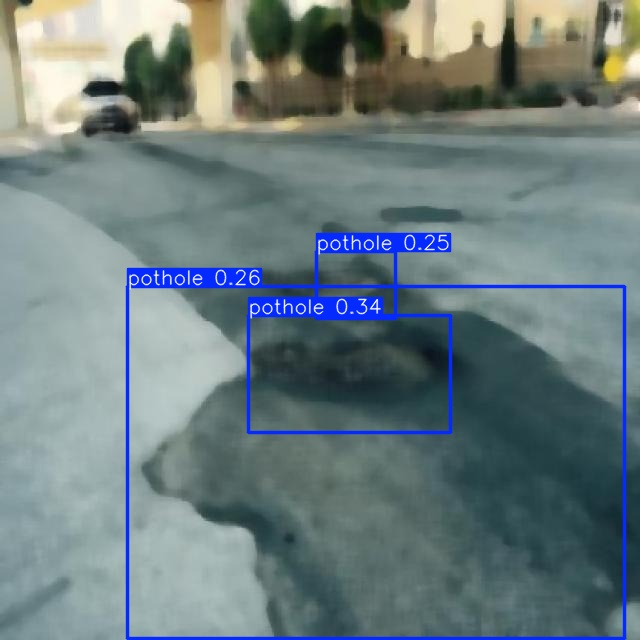

In [ ]:
from IPython.display import Image, display
import os

output_path = "/content/runs/detect/predict/"

# show first detected image
for file in os.listdir(output_path):
    if file.endswith(".jpg") or file.endswith(".png"):
        display(Image(filename=os.path.join(output_path, file)))
        break


In [ ]:
!yolo task=detect mode=val model="/content/YOLO-based-Pothole-Detection-main/best.pt" data="/content/dataset/data.yaml"


Ultralytics 8.3.226 🚀 Python-3.12.12 torch-2.8.0+cu126 CPU (Intel Xeon CPU @ 2.20GHz)
Model summary (fused): 112 layers, 43,607,379 parameters, 0 gradients, 164.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1074.0±397.8 MB/s, size: 28.8 KB)
val: Scanning /content/dataset/valid/labels... 21 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 21/21 195.9it/s 0.1s
val: New cache created: /content/dataset/valid/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 0.0it/s 1:42
                   all         21         35      0.587      0.486      0.538        0.2
Speed: 31.3ms preprocess, 4812.8ms inference, 0.0ms loss, 1.5ms postprocess per image
Results saved to /content/runs/detect/val
💡 Learn more at https://docs.ultralytics.com/modes/val


In [ ]:
!zip -r /content/pothole_predictions.zip /content/runs/detect/predict/


  adding: content/runs/detect/predict/ (stored 0%)
  adding: content/runs/detect/predict/1_jpg.rf.476e18695062dba220457154568b432d.jpg (deflated 5%)
  adding: content/runs/detect/predict/142_jpg.rf.2b34509bb1e1fd45263a5e266840caac.jpg (deflated 5%)
  adding: content/runs/detect/predict/200_jpg.rf.a99777062f2afc40a09dcaae18ddc7f4.jpg (deflated 5%)
  adding: content/runs/detect/predict/215_jpg.rf.2d95fa87bbfb9779fccdf66d63cd8284.jpg (deflated 3%)
  adding: content/runs/detect/predict/115_jpg.rf.6f81e6f36197d06d6859926ae724a21f.jpg (deflated 7%)
  adding: content/runs/detect/predict/131_jpg.rf.eaec717493c35976ef9b3f0be17cfc16.jpg (deflated 3%)
  adding: content/runs/detect/predict/54_jpg.rf.ac474881396305e4c770576c2a5193c6.jpg (deflated 4%)
  adding: content/runs/detect/predict/151_jpg.rf.990469df330a22918cbe843482a5c21f.jpg (deflated 5%)
  adding: content/runs/detect/predict/68_jpg.rf.22caf5f132dde1fc0afe4bd6e5e1e6cf.jpg (deflated 3%)
  adding: content/runs/detect/predict/149_jpg.rf.7f96

In [ ]:
!yolo task=detect mode=train model=yolov8n.pt data=/content/dataset/data.yaml epochs=30 imgsz=640 batch=16


Ultralytics 8.3.226 🚀 Python-3.12.12 torch-2.8.0+cu126 CPU (Intel Xeon CPU @ 2.20GHz)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset/data.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=False, name=train, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=100, perspective=0.0, plots=True, pose=1